# Dự báo mức độ nhu cầu thuê xe đạp (Bike Sharing) — Classification

Bộ dữ liệu `hour.csv` (UCI Bike Sharing, số lượt thuê xe theo giờ, 2011–2012). Bài toán: phân loại mức độ nhu cầu của mỗi giờ thành 3 lớp **thấp / vừa / cao** dựa trên `cnt`.

**Cấu trúc notebook**

| Phần | Nội dung |
|---|---|
| 0 | Thiết lập & load dữ liệu |
| A | Chia tập theo thời gian, sanity check, gán nhãn & EDA |
| B | Tiền xử lý (one-hot, cyclical encoding, loại cột) |
| C | Huấn luyện & so sánh các mô hình (trên Val) |
| D | Feature selection |
| E | Hyperparameter tuning (Random Forest, XGBoost) |
| F | Huấn luyện mô hình cuối (Train + Val) & chấm Test |
| G | Model Evaluation — trực quan hoá hiệu suất trên Test |

**Nguyên tắc chống data leakage:** chia train/val/test theo thời gian ngay sau khi tạo feature lag (lag chỉ dùng quá khứ nên không rò rỉ); sanity check chỉ trên `train + val`; ngưỡng nhãn, EDA, encoder, scaler, feature selection đều chỉ fit trên `train`; `test` chỉ được chấm đúng một lần ở Phần F và đánh giá ở Phần G.

# Phần 0 — Thiết lập & Load dữ liệu

## Thiết lập & load dữ liệu

Dữ liệu được sort theo (`dteday`, `hr`) ngay khi load vì mọi bước sau (chia theo thời gian, lag) đều phụ thuộc vào thứ tự thời gian. Sửa `DATA_PATH` nếu file nằm ở thư mục khác.

In [36]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import label_binarize
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report,
                             confusion_matrix, balanced_accuracy_score, cohen_kappa_score, roc_auc_score,
                             roc_curve, auc, precision_recall_curve, average_precision_score,
                             precision_recall_fscore_support)
from sklearn.model_selection import GridSearchCV, PredefinedSplit

pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

seed = 42
DATA_PATH = "D:/Machine Learning/Midterm/data/raw/hour.csv"
TEST_SIZE = 0.2
VAL_SIZE = 0.2
DEMAND_LEVEL_LABELS = {0: "low", 1: "medium", 2: "high"}
CYCLICAL_FEATURES = {"hr": 24, "mnth": 12, "weekday": 7}
ONE_HOT_FEATURES = ["season", "weathersit"]

In [37]:
df = pd.read_csv(DATA_PATH)
df["dteday"] = pd.to_datetime(df["dteday"])
df = df.sort_values(["dteday", "hr"]).reset_index(drop=True)
print("Shape:", df.shape)
df.head()

Shape: (17379, 17)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


# Phần A — Chia tập, Sanity check & EDA

## A1. Feature lag và chia tập theo thời gian

Trước khi chia tập dữ liệu, chúng ta sẽ tạo thêm 2 features mới là `lag_1h` (giá trị của cột `cnt` ở giờ trước đó) và `same_hour_prev` (giá trị của cột `cnt` ở cùng giờ trong ngày trước đó). 

Lag chỉ dùng giá trị **quá khứ** của `cnt` nên tạo trước khi chia không làm rò rỉ thông tin tương lai; các dòng đầu tập/đầu mỗi khoảng thiếu giờ sẽ có NaN và bị bỏ ở Phần B.

In [38]:
df["time_full"] = df["dteday"] + pd.to_timedelta(df["hr"], unit="h")
df["gap_hours"] = df["time_full"].diff().dt.total_seconds() / 3600

df["lag_1h"] = df["cnt"].shift(1)
df.loc[df["gap_hours"] != 1, "lag_1h"] = np.nan

same_hour_prev_map = df.set_index("time_full")["cnt"]
prev_day_time = df["time_full"] - pd.Timedelta(days=1)
df["same_hour_prev"] = prev_day_time.map(same_hour_prev_map)

lag_cols = ["lag_1h", "same_hour_prev"]
print("NaN count:")
print(df[lag_cols].isna().sum())

NaN count:
lag_1h             76
same_hour_prev    160
dtype: int64


In [39]:
df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,time_full,gap_hours,lag_1h,same_hour_prev
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16,2011-01-01 00:00:00,NaN,NaN,NaN
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40,2011-01-01 01:00:00,1.0,16.0,NaN
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32,2011-01-01 02:00:00,1.0,40.0,NaN
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13,2011-01-01 03:00:00,1.0,32.0,NaN
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1,2011-01-01 04:00:00,1.0,13.0,NaN


Vì là chuỗi thời gian, dữ liệu được chia **tuần tự** (đã sort theo `dteday`, `hr`, cắt theo tỉ lệ 60/20/20), không chia ngẫu nhiên, để tránh rò rỉ thông tin tương lai vào tập train. Bước chia chỉ dựa vào thứ tự thời gian và tỉ lệ `TEST_SIZE` / `VAL_SIZE`, **không dùng bất kỳ thống kê nào của dữ liệu**, nên làm trước sanity check.

Sau bước này: `train_df` + `val_df` → sanity check (`trainval_df`); `train_df` → ngưỡng nhãn và EDA; `test_df` → **khoá lại**, không dùng cho đến Phần F.

In [40]:
n = len(df)
n_test = int(n * TEST_SIZE)
n_val = int(n * VAL_SIZE)
n_train = n - n_test - n_val

train_df = df.iloc[:n_train].copy()
val_df = df.iloc[n_train:n_train + n_val].copy()
test_df = df.iloc[n_train + n_val:].copy()
for name, part in [("train", train_df), ("val", val_df), ("test", test_df)]:
    print(f"{name:5s}: {len(part)} rows | {part['dteday'].min().date()} -> {part['dteday'].max().date()}")

# Đảm bảo 3 tập không chồng lấn và đủ số dòng
assert len(train_df) + len(val_df) + len(test_df) == n
assert not (set(train_df["instant"]) & set(val_df["instant"]))
assert not (set(train_df["instant"]) & set(test_df["instant"]))
assert not (set(val_df["instant"]) & set(test_df["instant"]))

# Tập dùng cho sanity check: chỉ train + val, KHÔNG có test
trainval_df = pd.concat([train_df, val_df]).reset_index(drop=True)
print("trainval_df:", trainval_df.shape)

train: 10429 rows | 2011-01-01 -> 2012-03-15
val  : 3475 rows | 2012-03-15 -> 2012-08-07
test : 3475 rows | 2012-08-07 -> 2012-12-31
trainval_df: (13904, 21)


In [41]:
train_df.head()

,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt,time_full,gap_hours,lag_1h,same_hour_prev
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16,2011-01-01 00:00:00,NaN,NaN,NaN
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40,2011-01-01 01:00:00,1.0,16.0,NaN
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32,2011-01-01 02:00:00,1.0,40.0,NaN
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13,2011-01-01 03:00:00,1.0,32.0,NaN
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1,2011-01-01 04:00:00,1.0,13.0,NaN


## A2. Sanity check (chỉ trên `train` + `val`)

Kiểm tra dữ liệu có "sạch" và đúng như mô tả trong `Readme.txt` không: kiểu dữ liệu, giá trị thiếu, dòng trùng lặp, ràng buộc `casual + registered = cnt`, miền giá trị và tính liên tục theo thời gian. Toàn bộ kiểm tra dùng `trainval_df`; **tập test không tham gia**.

In [42]:
# Chỉ kiểm tra các cột gốc của dataset (bỏ các cột lag / thời gian do mình tự tạo, vì chúng có NaN theo thiết kế)
helper_cols = lag_cols + ["time_full", "gap_hours"]
raw_check_df = trainval_df.drop(columns=helper_cols)

print(raw_check_df.dtypes, end="\n\n")
print("Missing values per column:")
print(raw_check_df.isna().sum(), end="\n\n")
print("Duplicate rows:", raw_check_df.duplicated().sum())
print("Duplicate (dteday, hr):", raw_check_df.duplicated(subset=["dteday", "hr"]).sum())
print("Rows where casual + registered != cnt:", (raw_check_df["casual"] + raw_check_df["registered"] != raw_check_df["cnt"]).sum(), end="\n\n")

# Miền giá trị của các cột hạng mục / nhị phân
range_checks = {"season": (1, 4), "weathersit": (1, 4), "hr": (0, 23), "weekday": (0, 6),
                "mnth": (1, 12), "holiday": (0, 1), "workingday": (0, 1), "yr": (0, 1)}
for col, (lo, hi) in range_checks.items():
    bad = raw_check_df[(raw_check_df[col] < lo) | (raw_check_df[col] > hi)]
    print(f"{col:12s} miền hợp lệ [{lo},{hi}] -> số giá trị ngoài miền: {len(bad)}")
print()

# Các cột số đã chuẩn hoá (nên nằm trong [0, 1])
for col in ["temp", "atemp", "hum", "windspeed"]:
    print(f"{col:10s} min={raw_check_df[col].min():.4f}  max={raw_check_df[col].max():.4f}")
print()

# Tính liên tục theo thời gian: khoảng kỳ vọng tính từ mốc đầu đến mốc cuối THỰC TẾ của train+val
# (ranh giới val/test có thể cắt giữa ngày nên không ép đến 23h)
full_dt = raw_check_df["dteday"] + pd.to_timedelta(raw_check_df["hr"], unit="h")
full_range = pd.date_range(full_dt.min(), full_dt.max(), freq="h")
missing_hours = full_range.difference(full_dt)
print("Date range (train+val):", full_dt.min(), "->", full_dt.max())
print("Expected hours:", len(full_range), "| Actual rows:", len(raw_check_df), "| Missing hours:", len(missing_hours))

instant                int64
dteday        datetime64[us]
season                 int64
yr                     int64
mnth                   int64
hr                     int64
holiday                int64
weekday                int64
workingday             int64
weathersit             int64
temp                 float64
atemp                float64
hum                  float64
windspeed            float64
casual                 int64
registered             int64
cnt                    int64
dtype: object

Missing values per column:
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64

Duplicate rows: 0
Duplicate (dteday, hr): 0
Rows where casual + registered != cnt: 0

season       miền hợp lệ [1,4] -> số giá trị ngoài miền: 0
weathersit   miền hợp lệ [1,4] -> 

**Nhận xét sanity check (trên train + val):**
- Không có NaN, không có dòng trùng lặp — đúng như dự kiến.
- `casual + registered = cnt` khớp 100% — dữ liệu đáng tin cậy.
- Tất cả cột hạng mục/nhị phân đều nằm đúng miền mô tả trong `Readme.txt`; các cột chuẩn hoá (`temp`, `atemp`, `hum`, `windspeed`) đều trong [0, 1].
- 125 giờ bị thiếu trong chuỗi thời gian của train+val (14.029 giờ kỳ vọng so với 13.904 dòng thực tế; khoảng thời gian của test không được kiểm tra) — không phải lỗi cần sửa nhưng phải ghi vào báo cáo và lưu ý khi làm feature time-series (lag, rolling).

→ Kết luận: dữ liệu sạch, sẵn sàng cho các bước tiếp theo.

## A3. Định nghĩa nhãn mục tiêu

Ngưỡng phân lớp tính **một lần duy nhất trên `train_df`** bằng quantile 33% / 67% của `cnt`: `cnt <= low` → thấp (0), `cnt <= high` → vừa (1), còn lại → cao (2). Chia theo quantile thay vì ngưỡng cố định để 3 lớp xấp xỉ cân bằng. Cùng một ngưỡng được áp cho val và test (không tính lại), nhưng **không xem phân phối nhãn của test**.

In [43]:
low = train_df["cnt"].quantile(0.33)
high = train_df["cnt"].quantile(0.67)
print("low =", low, "| high =", high)

def assign_demand_level(cnt):
    if cnt <= low:
        return 0
    elif cnt <= high:
        return 1
    else:
        return 2

for d in [train_df, val_df, test_df]:
    d["demand_level"] = d["cnt"].apply(assign_demand_level)
print("\nLabel Distribution (Train)")
print(train_df["demand_level"].map(DEMAND_LEVEL_LABELS).value_counts())

low = 56.0 | high = 176.0

Label Distribution (Train)
demand_level
medium    3539
low       3459
high      3431
Name: count, dtype: int64


## A4. Khám phá dữ liệu (trên `train_df`)

Chỉ "nhìn" vào tập train để tránh rò rỉ thông tin từ val/test (val chỉ dùng để đối chiếu phân phối lớp ở A4.5).

,cnt,casual,registered,temp,atemp,hum,windspeed
count,10429.000000,10429.000000,10429.000000,10429.000000,10429.000000,10429.000000,10429.000000
mean,144.821364,26.341164,118.480199,0.459726,0.442693,0.630609,0.195566
std,134.619510,37.208306,112.645389,0.197397,0.177321,0.197797,0.125688
min,1.000000,0.000000,0.000000,0.020000,0.000000,0.000000,0.000000
25%,32.000000,3.000000,27.000000,0.300000,0.303000,0.470000,0.104500
50%,111.000000,12.000000,93.000000,0.440000,0.439400,0.620000,0.194000
75%,213.000000,34.000000,171.000000,0.620000,0.590900,0.790000,0.283600
max,782.000000,272.000000,647.000000,0.960000,1.000000,1.000000,0.850700


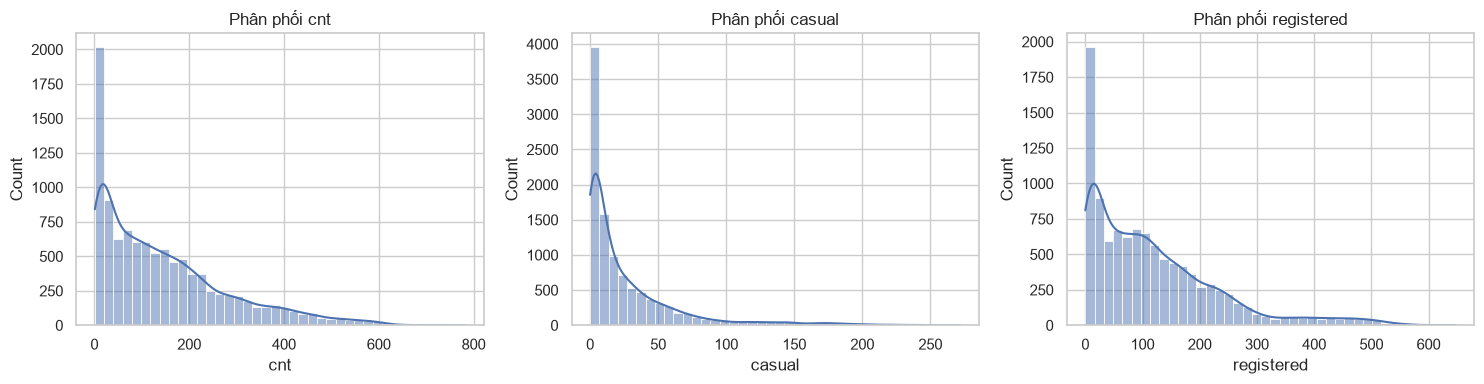

In [44]:
display(train_df[["cnt", "casual", "registered", "temp", "atemp", "hum", "windspeed"]].describe())

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["cnt", "casual", "registered"]):
    sns.histplot(train_df[col], bins=40, ax=ax, kde=True)
    ax.set_title(f"Phân phối {col}")
plt.tight_layout()
plt.show()

### A3.1. Pattern theo giờ trong ngày — tách ngày làm việc / cuối tuần

So sánh hành vi người dùng **casual** (thường đi chơi/giải trí) và **registered** (thường đi làm) theo từng giờ, tách riêng `workingday` để thấy 2 kiểu pattern khác nhau.

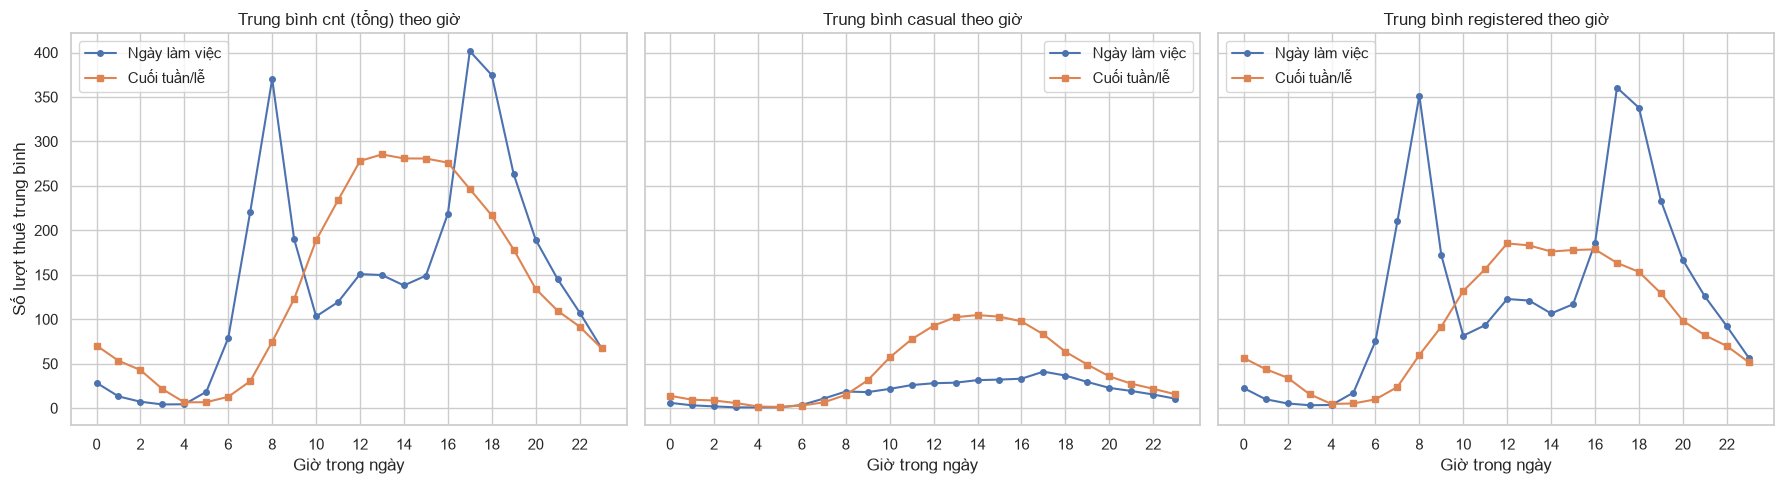

In [45]:
hourly = train_df.groupby(["workingday", "hr"])[["cnt", "casual", "registered"]].mean().reset_index()

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, col, title in zip(axes, ["cnt", "casual", "registered"], ["cnt (tổng)", "casual", "registered"]):
    for wd, label, style in [(1, "Ngày làm việc", "-o"), (0, "Cuối tuần/lễ", "-s")]:
        sub = hourly[hourly["workingday"] == wd]
        ax.plot(sub["hr"], sub[col], style, label=label, markersize=4)
    ax.set_title(f"Trung bình {title} theo giờ")
    ax.set_xlabel("Giờ trong ngày")
    ax.set_xticks(range(0, 24, 2))
    ax.legend()
axes[0].set_ylabel("Số lượt thuê trung bình")
plt.tight_layout()
plt.show()

**Nhận xét** (số liệu là trung bình theo giờ trên `train_df`):

- **cnt (tổng):** ngày làm việc có 2 đỉnh rõ rệt — ~8h (≈370) và ~17h (≈400, đỉnh cao nhất trong ngày); cuối tuần/lễ chỉ có 1 đỉnh thoải quanh 12h–15h (≈285).
- **casual:** đường cuối tuần/lễ cao hơn hẳn ngày làm việc ở mọi giờ từ 10h–18h (đỉnh cuối tuần ≈105 lúc ~14h, trong khi đỉnh ngày làm việc chỉ ≈41) — đúng như dự đoán, khách casual đi chơi/giải trí nên tập trung cuối tuần, ban ngày.
- **registered:** gần như bản sao của đường `cnt` — 2 đỉnh giờ đi làm/tan làm ở ngày làm việc (≈350 lúc 8h, ≈360 lúc 17h), còn cuối tuần phẳng hơn, đỉnh ≈185 quanh 12h.

→ Bằng chứng cho nhận xét "2 nhóm người dùng có mục đích khác nhau": registered = đi làm (commute), casual = giải trí (leisure). Vì registered chiếm tỷ trọng lớn trong `cnt` nên đường `cnt` gần giống đường registered.

### A3.2. Phân bố các feature quan trọng theo từng lớp nhu cầu

Xem feature nào tách 3 lớp (thấp/vừa/cao) rõ nhất.

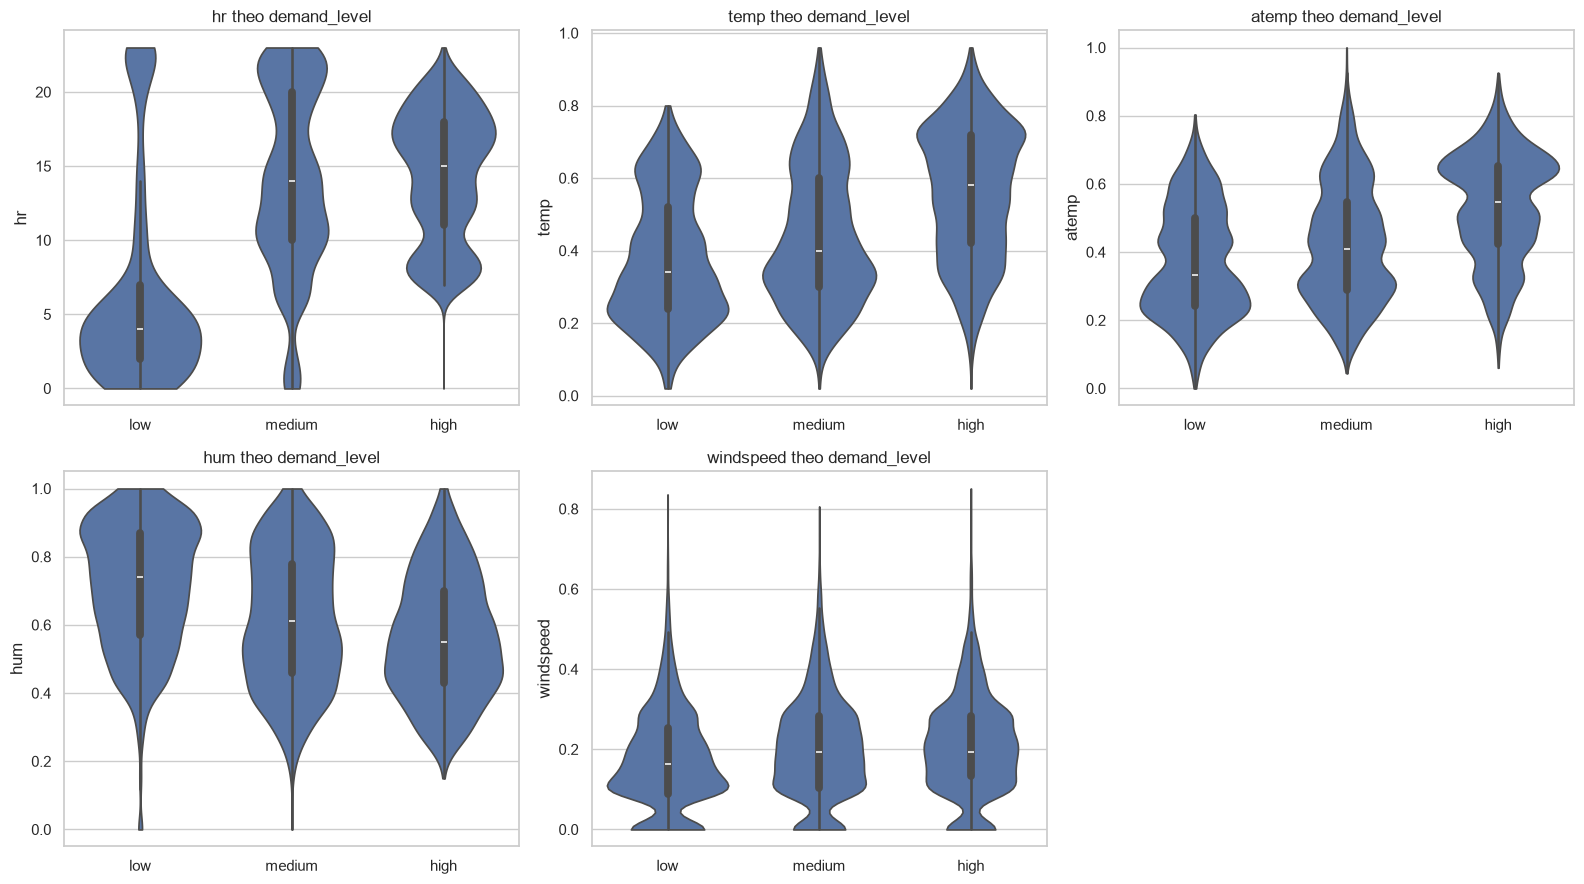

In [46]:
label_names = list(DEMAND_LEVEL_LABELS.values())
plot_df = train_df.assign(demand_label=train_df["demand_level"].map(DEMAND_LEVEL_LABELS))

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()
for ax, feat in zip(axes, ["hr", "temp", "atemp", "hum", "windspeed"]):
    sns.violinplot(data=plot_df, x="demand_label", y=feat, order=label_names, ax=ax, cut=0)
    ax.set_title(f"{feat} theo demand_level")
    ax.set_xlabel("")
axes[-1].axis("off")
plt.tight_layout()
plt.show()

**Nhận xét:**

- **hr:** tách rõ nhất — lớp low tập trung ở khung giờ đêm khuya/sáng sớm (trung vị 4h), trong khi medium/high trải ở khung giờ ban ngày/cao điểm (trung vị 14–15h).
- **temp, atemp:** median tăng dần từ low → medium → high (trời càng ấm, nhu cầu càng cao) — tách lớp khá rõ, nhất là giữa low và high.
- **hum:** xu hướng ngược lại — median giảm dần từ low → high (độ ẩm thấp thì nhu cầu cao hơn, hợp lý vì ẩm cao thường đi kèm mưa/khó chịu).
- **windspeed:** 3 lớp chồng lấn nhiều nhất, median gần như không khác biệt → feature phân biệt lớp kém nhất trong 5 feature.

→ Xếp hạng mức độ hữu ích cho phân loại: `hr` > `temp`/`atemp` ≈ `hum` > `windspeed`.

### A3.3. Ma trận tương quan giữa các biến số

Kiểm tra đặc biệt cặp `temp` / `atemp`, thường tương quan rất cao (đa cộng tuyến).

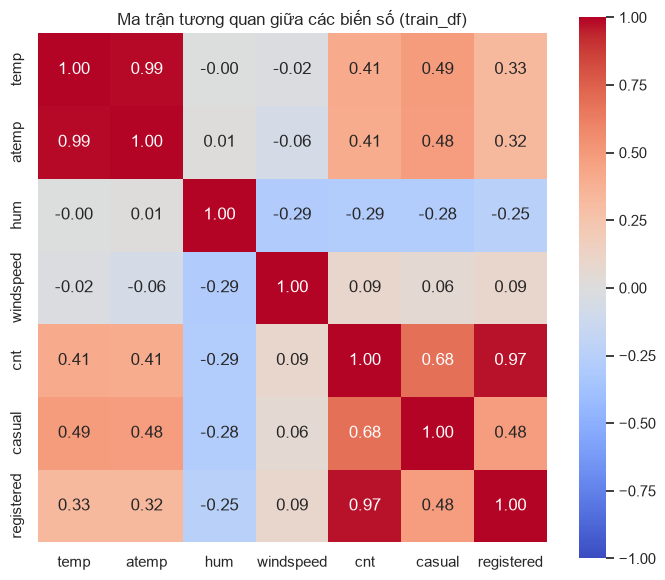

Correlation temp vs atemp: 0.992


In [47]:
corr = train_df[["temp", "atemp", "hum", "windspeed", "cnt", "casual", "registered"]].corr()

plt.figure(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True)
plt.title("Ma trận tương quan giữa các biến số (train_df)")
plt.tight_layout()
plt.show()

print(f"Correlation temp vs atemp: {corr.loc['temp', 'atemp']:.3f}")

**Nhận xét:** tương quan `temp`–`atemp` = 0.992 (> 0.9) → nên loại bỏ 1 trong 2 biến (giữ `atemp` vì phản ánh cảm nhận thực tế của người dùng hơn) để tránh đa cộng tuyến khi dùng mô hình tuyến tính như Logistic Regression.

### A3.4. Phân phối lớp (class balance)

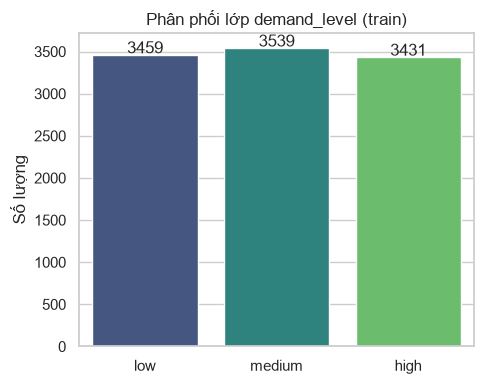

In [48]:
counts = train_df["demand_level"].map(DEMAND_LEVEL_LABELS).value_counts().reindex(label_names)

plt.figure(figsize=(5, 4))
sns.barplot(x=counts.index, y=counts.values, hue=counts.index, palette="viridis", legend=False)
plt.title("Phân phối lớp demand_level (train)")
plt.ylabel("Số lượng")
plt.xlabel("")
for i, v in enumerate(counts.values):
    plt.text(i, v + 20, str(v), ha="center")
plt.tight_layout()
plt.show()

**Nhận xét:** nhờ chia theo quantile 33/67 trên `train_df`, 3 lớp gần như cân bằng tuyệt đối (low 3459, medium 3539, high 3431; chênh lệch < 2%).

### A4.5. Đối chiếu phân phối lớp: train vs val

Ngưỡng được tính trên `train_df` rồi áp dụng nguyên xi cho `val_df` (không tính lại trên val). Kỳ vọng: phân phối lớp ở val **lệch rất mạnh** so với train (train ≈ 33/34/33% nhưng val ≈ 23/17/60% theo kết quả đã chạy), do chia theo thời gian nên val rơi vào giai đoạn xuân–hè 2012 khi nhu cầu thuê xe tăng rõ so với 2011 — đây là *distribution shift* theo thời gian, không phải lỗi code.

Hệ quả: (1) không chỉnh lại ngưỡng theo val (sẽ gây rò rỉ); (2) accuracy có thể bị lớp *high* chi phối → dùng **Macro F1** và confusion matrix; (3) ghi rõ điểm này trong báo cáo.

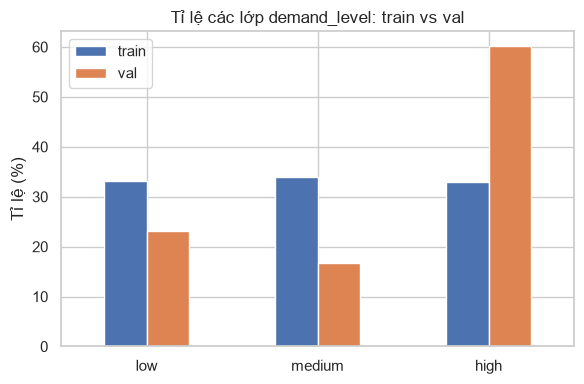

              train   val
demand_level             
low            33.2  23.2
medium         33.9  16.7
high           32.9  60.1


In [49]:
order = ["low", "medium", "high"]
dist = pd.DataFrame({
    "train": train_df["demand_level"].map(DEMAND_LEVEL_LABELS).value_counts(normalize=True).reindex(order),
    "val": val_df["demand_level"].map(DEMAND_LEVEL_LABELS).value_counts(normalize=True).reindex(order),
})

ax = (dist * 100).plot(kind="bar", figsize=(6, 4), rot=0)
ax.set_title("Tỉ lệ các lớp demand_level: train vs val")
ax.set_ylabel("Tỉ lệ (%)")
ax.set_xlabel("")
plt.tight_layout()
plt.show()

print((dist * 100).round(1))

## Kết luận EDA

- Dữ liệu sạch, không có NaN hay dòng trùng; cần ghi nhận 165 giờ bị thiếu trong chuỗi thời gian.
- Ngưỡng phân lớp: `low = 56.0`, `high = 176.0` (quantile 33%/67% của `cnt` trên `train_df`); 3 lớp cân bằng.
- Thứ tự ưu tiên feature theo EDA: `hr` > `temp`/`atemp` > `hum` >> `windspeed`; `temp` và `atemp` đa cộng tuyến (0.992) nên chỉ giữ một.
- Hai nhóm người dùng có pattern khác nhau rõ rệt (registered: giờ đi làm; casual: giải trí cuối tuần) → `hr` và `workingday` là thông tin quan trọng.
- Metric đề xuất: vì 3 lớp cân bằng, accuracy vẫn dùng được, nên theo dõi thêm macro-F1 và confusion matrix (dự kiến lớp medium dễ bị nhầm với cả low và high vì nằm giữa).

# Phần B — Tiền xử lý

Các bước ở đây **không chia lại** train/val/test: dùng đúng `train_df`, `val_df`, `test_df` đã tách ở Phần A. Encoder chỉ `fit` trên train rồi `transform` cho val/test. Các dòng NaN do lag bị bỏ khỏi từng tập.

In [50]:
train_df.dropna(inplace=True)
val_df.dropna(inplace=True)
test_df.dropna(inplace=True)

In [52]:
def preprocess_features(data):
    d = data.copy()
    
    for col, max_val in CYCLICAL_FEATURES.items():
        d[f'{col}_sin'] = np.sin(2 * np.pi * d[col] / max_val)
        d[f'{col}_cos'] = np.cos(2 * np.pi * d[col] / max_val)
        d = d.drop(columns=[col])
        
    cols_to_drop = ['instant', 'dteday', 'casual', 'registered', 'cnt', 
                    'time_full', 'gap_hours', "yr", "temp"]
    d = d.drop(columns=[c for c in cols_to_drop if c in d.columns])
    
    return d

x_train = preprocess_features(train_df.drop(columns=['demand_level']))
y_train = train_df['demand_level']

x_val = preprocess_features(val_df.drop(columns=['demand_level']))
y_val = val_df['demand_level']

x_test = preprocess_features(test_df.drop(columns=['demand_level']))
y_test = test_df['demand_level']

In [53]:
print(len(x_train.columns))
x_train.columns.tolist()

19


['holiday',
 'workingday',
 'atemp',
 'hum',
 'windspeed',
 'lag_1h',
 'same_hour_prev',
 'season_2',
 'season_3',
 'season_4',
 'weathersit_2',
 'weathersit_3',
 'weathersit_4',
 'hr_sin',
 'hr_cos',
 'mnth_sin',
 'mnth_cos',
 'weekday_sin',
 'weekday_cos']

In [54]:
print(len(x_val.columns))
x_val.columns.tolist()

19


['holiday',
 'workingday',
 'atemp',
 'hum',
 'windspeed',
 'lag_1h',
 'same_hour_prev',
 'season_2',
 'season_3',
 'season_4',
 'weathersit_2',
 'weathersit_3',
 'weathersit_4',
 'hr_sin',
 'hr_cos',
 'mnth_sin',
 'mnth_cos',
 'weekday_sin',
 'weekday_cos']

In [55]:
print(len(x_test.columns))
x_test.columns.tolist()

19


['holiday',
 'workingday',
 'atemp',
 'hum',
 'windspeed',
 'lag_1h',
 'same_hour_prev',
 'season_2',
 'season_3',
 'season_4',
 'weathersit_2',
 'weathersit_3',
 'weathersit_4',
 'hr_sin',
 'hr_cos',
 'mnth_sin',
 'mnth_cos',
 'weekday_sin',
 'weekday_cos']

# Phần C — Huấn luyện & so sánh mô hình (trên Val)

In [56]:
def get_models(random_state=42):
    return {
        "Logistic Regression": make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000, random_state=random_state)),
        "KNN": make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5)),
        "Decision Tree": DecisionTreeClassifier(random_state=random_state),
        "Random Forest": RandomForestClassifier(n_estimators=200, random_state=random_state, n_jobs=-1),
        "XGBoost": XGBClassifier(n_estimators=200, eval_metric="mlogloss", random_state=random_state, n_jobs=-1),
    }

def evaluate(model, X, y):
    y_pred = model.predict(X)
    return {
        "Accuracy": accuracy_score(y, y_pred),
        "Macro Precision": precision_score(y, y_pred, average="macro", zero_division=0),
        "Macro Recall": recall_score(y, y_pred, average="macro", zero_division=0),
        "Macro F1": f1_score(y, y_pred, average="macro", zero_division=0),
    }

def train_and_evaluate(X_train, y_train, X_val, y_val, features=None, random_state=42):
    if features is not None:
        X_train, X_val = X_train[features], X_val[features]

    fitted, results = {}, {}
    for name, model in get_models(random_state).items():
        print(f"Training {name}...")
        model.fit(X_train, y_train)               # chỉ fit trên train
        train_scores = evaluate(model, X_train, y_train)
        val_scores = evaluate(model, X_val, y_val)  # chấm trên val
        results[name] = {
            "Train Macro F1": train_scores["Macro F1"],
            "Val Macro F1": val_scores["Macro F1"],
            "Val Accuracy": val_scores["Accuracy"],
            "Val Macro Precision": val_scores["Macro Precision"],
            "Val Macro Recall": val_scores["Macro Recall"],   
            "Gap (Train-Val F1)": train_scores["Macro F1"] - val_scores["Macro F1"],
        }
        fitted[name] = model

    results_df = pd.DataFrame.from_dict(results, orient="index").sort_values("Val Macro F1", ascending=False).round(4)
    print("\nModel comparison (validation set):")
    print(results_df)
    return fitted, results_df

In [57]:
fitted_models, val_results = train_and_evaluate(
    x_train, y_train,
    x_val, y_val
)

Training Logistic Regression...
Training KNN...
Training Decision Tree...
Training Random Forest...
Training XGBoost...

Model comparison (validation set):
                     Train Macro F1  Val Macro F1  Val Accuracy  \
Random Forest                1.0000        0.8875        0.9162   
XGBoost                      1.0000        0.8831        0.9116   
Logistic Regression          0.8102        0.8287        0.8827   
Decision Tree                1.0000        0.8243        0.8666   
KNN                          0.8846        0.7685        0.8217   

                     Val Macro Precision  Val Macro Recall  Gap (Train-Val F1)  
Random Forest                     0.8769            0.9002              0.1125  
XGBoost                           0.8710            0.8990              0.1169  
Logistic Regression               0.8313            0.8262             -0.0185  
Decision Tree                     0.8144            0.8372              0.1757  
KNN                               0.

## 1. Tiền xử lý dữ liệu & Chống Rò rỉ (Data Leakage)
- **Quy tắc:** Mọi bước tính toán ngưỡng nhãn (quantile), fit `StandardScaler`, fit `OneHotEncoder`, và tính độ quan trọng của đặc trưng (Feature Importance) **chỉ được thực hiện trên tập Train**, sau đó mới `transform` lên Val và Test.
- **Xử lý đặc trưng tuần hoàn:** Các cặp biến góc thời gian (`_sin` và `_cos`) **phải luôn đi chung với nhau**, tuyệt đối không tách rời khi chọn lọc đặc trưng.
- **Metric đánh giá:** Do tập Val/Test bị lệch phân phối mạnh về lớp "High" (do nhu cầu thuê xe năm 2012 tăng cao), **phải sử dụng `Macro F1`** làm thước đo chính thay vì Accuracy hay Weighted F1 để tránh bị che khuất lỗi ở các lớp nhỏ (Low/Medium).

## 2. Overfitting & Lưu ý Hyperparameter Tuning
- **Hiện tượng Gap lớn:** Nếu Train Macro F1 đạt `1.0000` nhưng Val chỉ quanh `0.82 - 0.88` (Gap ~ 11% - 18%), mô hình đang bị học vẹt (Overfitting).
- **Chiến lược Tuning:** 
  - Chỉ tập trung tune Top 2 mô hình mạnh nhất (**Random Forest** và **XGBoost**).
  - Tập trung vào các tham số chống quá khớp: 
    - *Random Forest:* `max_depth`, `min_samples_leaf`.
    - *XGBoost:* `max_depth`, `learning_rate`, `subsample`, `colsample_bytree`.

## 3. Quy trình Gộp Train + Val & Đánh giá Cuối cùng (Final Test)
Khi đã chọn được danh sách feature tối ưu và bộ siêu tham số tốt nhất:
1. **Cố định cấu hình:** Giữ nguyên danh sách feature và hyperparameter, tuyệt đối không thay đổi hay dò lại nữa.
2. **Gộp dữ liệu:** Ghép `Train` và `Val` lại thành một tập dữ liệu lớn hơn để mô hình học được nhiều mẫu hơn (hữu ích khi Val chứa phân phối nhu cầu cao của năm 2012).
3. **Lưu ý khi gộp:**
   - Giữ nguyên ngưỡng phân loại nhãn ban đầu (không tính lại quantile trên tập gộp).
   - Với XGBoost, cố định số lượng cây (`n_estimators`) theo kết quả tuning trước đó, **không bật early stopping** trên tập gộp.
   - Pipeline (`StandardScaler`) sẽ tự động `fit` lại mean/std trên toàn bộ không gian dữ liệu gộp mới này.
4. **Chấm điểm Test (Đúng 1 lần duy nhất):** Đưa tập Test vào mô hình đã huấn luyện trên `Train + Val` để lấy kết quả cuối cùng báo cáo. Tuyệt đối không để tập Test tham gia vào bất kỳ bước xử lý nào trước đó.

# Phần D — Feature selection

Sử dụng 3 phương pháp, Mutual Information (model-free), Gini Importance, Permutation Importance để chọn các feature ảnh hưởng nhất tới điểm chính xác

Cell bên dưới tự xử lý các dòng NaN của feature lag, huấn luyện `model_rf` trên đúng tập dữ liệu đã căn chỉnh, rồi tính cả ba loại importance.

In [58]:
rf_selector = fitted_models["Random Forest"]
discrete_col = x_train.nunique() <= 2

# permutation importance
perm_res = permutation_importance(
    rf_selector, x_train, y_train,
    scoring="f1_macro",
    n_repeats=10, 
    random_state=seed,
    n_jobs=-1
)
perm_series = pd.Series(perm_res.importances_mean, index=x_train.columns)

# mutual information
mi_res = mutual_info_classif(x_train, y_train, discrete_features=discrete_col, random_state=seed)
mi_series = pd.Series(mi_res, index=x_train.columns)

# gini importance (feature importances)
gini_series = pd.Series(rf_selector.feature_importances_, index=x_train.columns)

importance_df = pd.DataFrame({
    "permutation": perm_series,
    "mutual_info": mi_series,
    "gini": gini_series
})
display(importance_df)

,permutation,mutual_info,gini
holiday,0.000000,0.000463,0.001961
workingday,0.007008,0.001454,0.015889
atemp,0.024207,0.092403,0.055328
hum,0.017933,0.070483,0.042339
windspeed,0.007564,0.011305,0.027571
lag_1h,0.400200,0.576876,0.324627
same_hour_prev,0.069308,0.453271,0.225676
season_2,0.000224,0.000869,0.003868
season_3,0.000569,0.010726,0.003704
season_4,0.000283,0.000378,0.003909


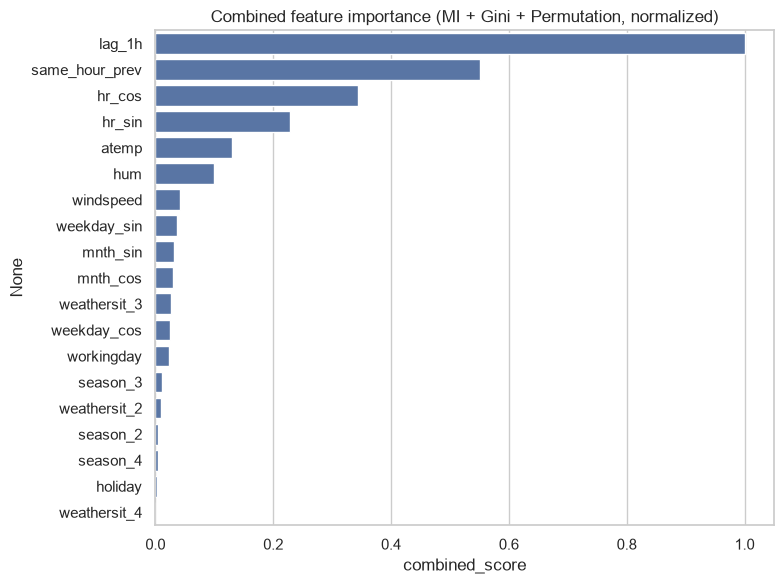

,permutation,mutual_info,gini,combined_score
lag_1h,1.000000,1.000000,1.000000,1.000000
same_hour_prev,0.173184,0.785734,0.695187,0.551368
hr_cos,0.307890,0.371573,0.349882,0.343115
hr_sin,0.103745,0.314374,0.268562,0.228894
atemp,0.060488,0.160179,0.170437,0.130368
hum,0.044811,0.122181,0.130422,0.099138
windspeed,0.018900,0.019597,0.084931,0.041142
weekday_sin,0.025814,0.017681,0.068595,0.037363
mnth_sin,0.013048,0.027292,0.054047,0.031462
mnth_cos,0.006639,0.030838,0.051527,0.029668


In [59]:
normalized = importance_df.apply(lambda col: col / col.max())
normalized["combined_score"] = normalized.mean(axis=1)
normalized = normalized.sort_values("combined_score", ascending=False)

fig, ax = plt.subplots(figsize=(8, 6))
sns.barplot(x=normalized["combined_score"], y=normalized.index, ax=ax)
ax.set_title("Combined feature importance (MI + Gini + Permutation, normalized)")
plt.tight_layout()
plt.show()

normalized

## Chọn tập feature rút gọn

In [60]:
top_features = normalized.index[:12].tolist()
print("Danh sách đặc trưng được giữ lại:")
print(top_features)

x_train_final = x_train[top_features]
x_val_final = x_val[top_features]
x_test_final = x_test[top_features]

# 3. (Tuỳ chọn) Chạy lại hàm train_and_evaluate để xem điểm số trên tập Val mới
fitted_final, results_final = train_and_evaluate(x_train_final, y_train, x_val_final, y_val)

Danh sách đặc trưng được giữ lại:
['lag_1h', 'same_hour_prev', 'hr_cos', 'hr_sin', 'atemp', 'hum', 'windspeed', 'weekday_sin', 'mnth_sin', 'mnth_cos', 'weathersit_3', 'weekday_cos']
Training Logistic Regression...
Training KNN...
Training Decision Tree...
Training Random Forest...
Training XGBoost...

Model comparison (validation set):
                     Train Macro F1  Val Macro F1  Val Accuracy  \
Random Forest                1.0000        0.8910        0.9205   
XGBoost                      1.0000        0.8786        0.9098   
Logistic Regression          0.8079        0.8308        0.8848   
Decision Tree                1.0000        0.8238        0.8657   
KNN                          0.8925        0.8049        0.8485   

                     Val Macro Precision  Val Macro Recall  Gap (Train-Val F1)  
Random Forest                     0.8838            0.8991              0.1090  
XGBoost                           0.8690            0.8909              0.1214  
Logistic Regress

# Phần E — Hyperparameter tuning

Chỉ tune Top 2 mô hình (Random Forest, XGBoost) bằng `GridSearchCV` + `PredefinedSplit`: học trên phần train, chấm trên phần val (không trộn lẫn, không dùng test), scoring = `f1_macro`.

In [ ]:
x_tune = pd.concat([x_train_final, x_val_final], axis=0)
y_tune = pd.concat([y_train, y_val], axis=0)

# dùng PredefinedSplit để đánh dấu phần học (train) và phần đánh giá (val) trong tập phát triển của 
# quá trình tuning hyperparameter. -1 = train, 0 = val 
test_fold = np.concatenate([
    np.full(len(x_train_final), -1),
    np.full(len(x_val_final), 0)
])
ps = PredefinedSplit(test_fold=test_fold)

# parameter setup for Random Forest
rf_param_grid = {
    "max_depth": [None, 8, 12, 15],
    "min_samples_split": [5, 10, 20],
    "min_samples_leaf": [2, 5, 10],
}
# parameter setup for XGBoost
xgb_param_grid = {
    'max_depth': [4, 6, 8],
    'learning_rate': [0.01, 0.05, 0.1],
    'subsample': [0.7, 0.8, 1.0],           
    'colsample_bytree': [0.7, 0.8, 1.0]   
}

# tunning
rf_grid = GridSearchCV(
    fitted_models["Random Forest"],
    param_grid=rf_param_grid,
    cv=ps,                  # Sử dụng phân tách Train/Val cố định
    scoring='f1_macro',     # Mục tiêu tối ưu là điểm Macro F1
    n_jobs=-1,
    verbose=1
)
rf_grid.fit(x_tune, y_tune)
print(f"RF Best Params: {rf_grid.best_params_}")
print(f"RF Best Val Macro-F1: {rf_grid.best_score_:.4f}\n")

xgb_grid = GridSearchCV(
    fitted_models["XGBoost"],
    param_grid=xgb_param_grid,
    cv=ps,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1
)
xgb_grid.fit(x_tune, y_tune)
print(f"XGB Best Params: {xgb_grid.best_params_}")
print(f"XGB Best Val Macro-F1: {xgb_grid.best_score_:.4f}")

Fitting 1 folds for each of 36 candidates, totalling 36 fits
RF Best Params: {'max_depth': 8, 'min_samples_leaf': 5, 'min_samples_split': 5}
RF Best Val Macro-F1: 0.8932

Fitting 1 folds for each of 81 candidates, totalling 81 fits
XGB Best Params: {'colsample_bytree': 0.8, 'learning_rate': 0.05, 'max_depth': 6, 'subsample': 0.7}
XGB Best Val Macro-F1: 0.8988


# Phần F — Mô hình cuối (Train + Val) & chấm Test

Cố định feature và hyperparameter đã chọn ở Phần D/E, huấn luyện lại trên `Train + Val`, rồi chấm **Test đúng một lần**.

In [62]:
final_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.05,
    colsample_bytree=0.8,
    subsample=0.7,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1
)

final_model.fit(x_tune, y_tune)
y_test_pred = final_model.predict(x_test_final)

print("\nEvaluation on Test Set:")
print(classification_report(y_test, y_test_pred, digits=4))


Evaluation on Test Set:
              precision    recall  f1-score   support

           0     0.9629    0.9453    0.9540       878
           1     0.8236    0.8721    0.8471       680
           2     0.9705    0.9581    0.9642      1886

    accuracy                         0.9379      3444
   macro avg     0.9190    0.9252    0.9218      3444
weighted avg     0.9395    0.9379    0.9385      3444



# Phần G — Model Evaluation trên Test

Các biểu đồ dưới đây chỉ dùng `final_model` (đã cố định ở Phần F) và `x_test_final / y_test`; **không** dùng test để chọn lại feature, hyperparameter hay mô hình.

| Biểu đồ | Trả lời câu hỏi |
|---|---|
| Bảng metric tổng hợp | Hiệu suất tổng thể (kể cả metric hợp với nhãn có thứ tự: Quadratic Weighted Kappa) |
| Confusion matrix (số lượng + chuẩn hoá theo hàng) | Lớp nào hay bị nhầm với lớp nào? Recall từng lớp? |
| Precision / Recall / F1 theo lớp | Lớp nào yếu nhất (đặc biệt khi test lệch về lớp High)? |
| ROC & Precision-Recall one-vs-rest | Mô hình tách từng lớp tốt thế nào, độc lập với ngưỡng chọn lớp? |
| Phân phối độ tự tin (max proba) đúng vs sai | Mô hình có "biết mình sai" không? |



## G1. Metric tổng hợp

In [63]:
y_proba = final_model.predict_proba(x_test_final)
class_names = [DEMAND_LEVEL_LABELS[i] for i in sorted(DEMAND_LEVEL_LABELS)]   # ["low", "medium", "high"]

metrics_test = pd.Series({
    "Accuracy": accuracy_score(y_test, y_test_pred),
    "Balanced accuracy": balanced_accuracy_score(y_test, y_test_pred),
    "Macro Precision": precision_score(y_test, y_test_pred, average="macro", zero_division=0),
    "Macro Recall": recall_score(y_test, y_test_pred, average="macro", zero_division=0),
    "Macro F1": f1_score(y_test, y_test_pred, average="macro", zero_division=0),
    "ROC-AUC (OvR, macro)": roc_auc_score(y_test, y_proba, multi_class="ovr", average="macro"),
}).round(4)
display(metrics_test.to_frame("Test"))

# Lớp có thứ tự low < medium < high -> sai lệch 1 bậc nhẹ hơn nhiều so với sai lệch 2 bậc (low <-> high)
err_dist = np.abs(np.asarray(y_test) - np.asarray(y_test_pred))
print(f"Dự đoán đúng      : {(err_dist == 0).mean():.2%}")
print(f"Sai lệch 1 bậc    : {(err_dist == 1).mean():.2%}")
print(f"Sai lệch 2 bậc    : {(err_dist == 2).mean():.2%}")

,Test
Accuracy,0.9379
Balanced accuracy,0.9252
Macro Precision,0.9190
Macro Recall,0.9252
Macro F1,0.9218
"ROC-AUC (OvR, macro)",0.9879


Dự đoán đúng      : 93.79%
Sai lệch 1 bậc    : 6.21%
Sai lệch 2 bậc    : 0.00%


## G2. Confusion matrix — số lượng và chuẩn hoá theo hàng

Ma trận bên phải chia mỗi hàng cho số mẫu thực tế của lớp đó → đường chéo chính chính là **recall từng lớp**, không bị che khuất khi test lệch về lớp High.

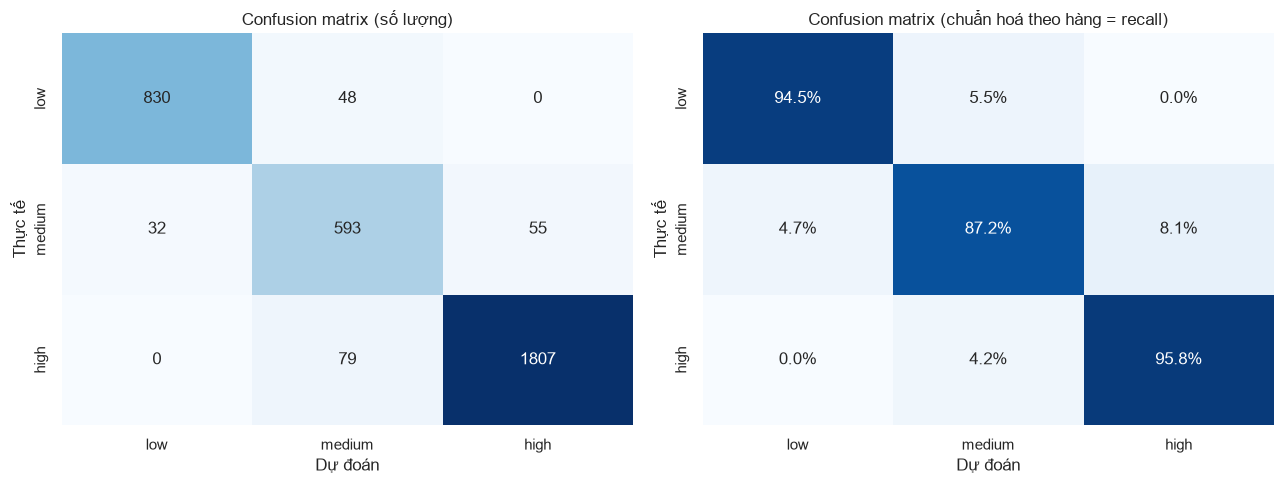

In [64]:
cm = confusion_matrix(y_test, y_test_pred, labels=[0, 1, 2])
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[0],
            xticklabels=class_names, yticklabels=class_names)
axes[0].set_title("Confusion matrix (số lượng)")
sns.heatmap(cm_norm, annot=True, fmt=".1%", cmap="Blues", vmin=0, vmax=1, cbar=False, ax=axes[1],
            xticklabels=class_names, yticklabels=class_names)
axes[1].set_title("Confusion matrix (chuẩn hoá theo hàng = recall)")
for ax in axes:
    ax.set_xlabel("Dự đoán")
    ax.set_ylabel("Thực tế")
plt.tight_layout()
plt.show()

## G3. Precision / Recall / F1 theo từng lớp

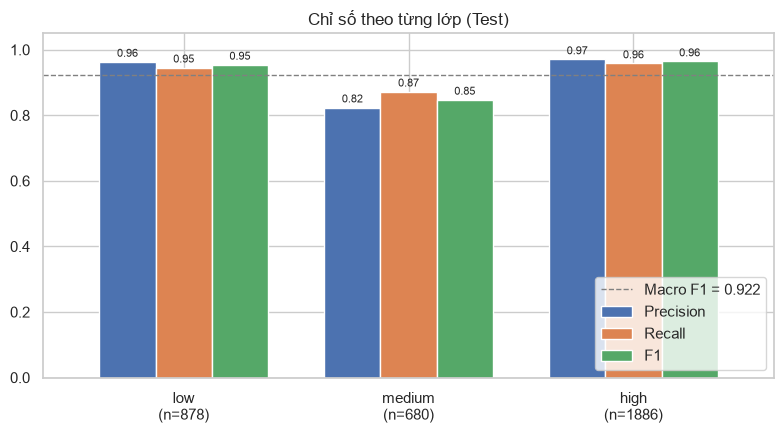

In [65]:
prec, rec, f1, support = precision_recall_fscore_support(y_test, y_test_pred, labels=[0, 1, 2], zero_division=0)
per_class = pd.DataFrame({"Precision": prec, "Recall": rec, "F1": f1}, index=class_names)

ax = per_class.plot(kind="bar", figsize=(8, 4.5), rot=0, width=0.75)
ax.axhline(metrics_test["Macro F1"], color="gray", ls="--", lw=1, label=f"Macro F1 = {metrics_test['Macro F1']:.3f}")
ax.set_ylim(0, 1.05)
ax.set_title("Chỉ số theo từng lớp (Test)")
ax.set_xlabel("")
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=8, padding=2)
ax.set_xticklabels([f"{c}\n(n={s})" for c, s in zip(class_names, support)])
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

## G4. ROC và Precision-Recall (one-vs-rest)

Mỗi lớp được coi là "positive" còn hai lớp kia là "negative". PR curve nhạy hơn ROC khi lớp lệch nhau (test lệch về High).

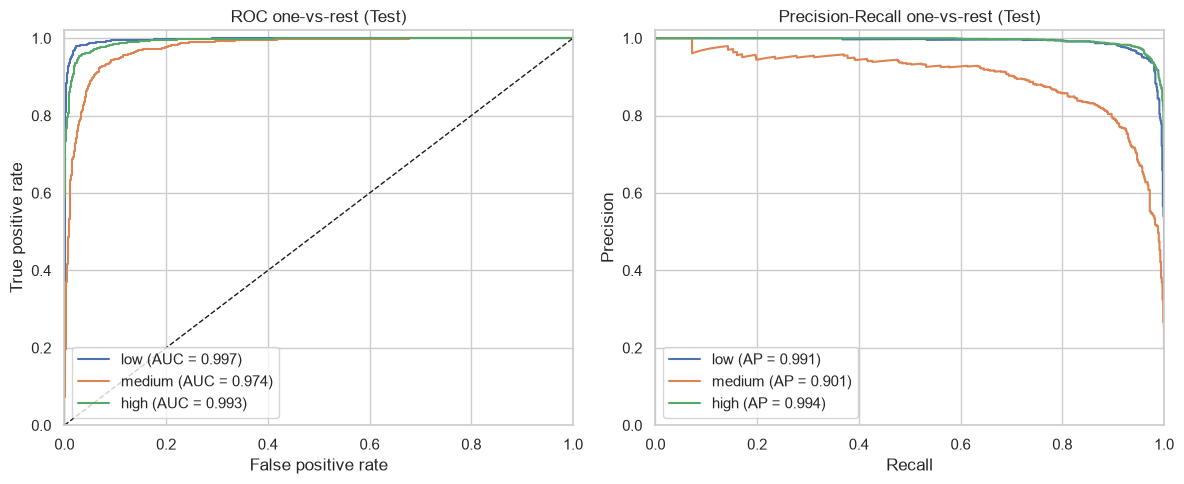

In [66]:
y_bin = label_binarize(y_test, classes=[0, 1, 2])

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for k, name in enumerate(class_names):
    fpr, tpr, _ = roc_curve(y_bin[:, k], y_proba[:, k])
    axes[0].plot(fpr, tpr, label=f"{name} (AUC = {auc(fpr, tpr):.3f})")
    p, r, _ = precision_recall_curve(y_bin[:, k], y_proba[:, k])
    axes[1].plot(r, p, label=f"{name} (AP = {average_precision_score(y_bin[:, k], y_proba[:, k]):.3f})")
axes[0].plot([0, 1], [0, 1], "k--", lw=1)
axes[0].set(title="ROC one-vs-rest (Test)", xlabel="False positive rate", ylabel="True positive rate")
axes[1].set(title="Precision-Recall one-vs-rest (Test)", xlabel="Recall", ylabel="Precision")
for ax in axes:
    ax.legend(loc="lower left" if ax is axes[0] else "lower left")
    ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
plt.tight_layout()
plt.show()

## G5. Độ tự tin của mô hình: dự đoán đúng vs sai

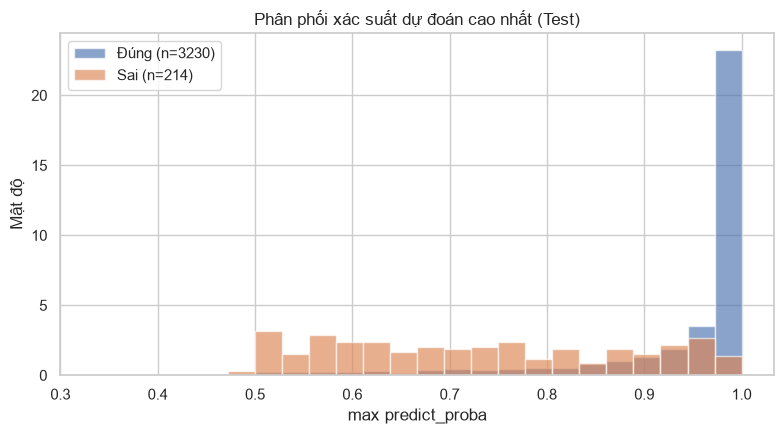

In [67]:
confidence = y_proba.max(axis=1)
is_correct = (np.asarray(y_test) == np.asarray(y_test_pred))

fig, ax = plt.subplots(figsize=(8, 4.5))
bins = np.linspace(1 / 3, 1, 25)
ax.hist(confidence[is_correct], bins=bins, alpha=0.65, label=f"Đúng (n={is_correct.sum()})", density=True)
ax.hist(confidence[~is_correct], bins=bins, alpha=0.65, label=f"Sai (n={(~is_correct).sum()})", density=True)
ax.set_title("Phân phối xác suất dự đoán cao nhất (Test)")
ax.set_xlabel("max predict_proba")
ax.set_ylabel("Mật độ")
ax.legend()
plt.tight_layout()
plt.show()

## Kết luận đánh giá

*(Điền sau khi chạy: lớp nào có recall thấp nhất, tỉ lệ sai lệch 2 bậc, accuracy có giảm theo thời gian trong test không, mô hình có đủ tự tin ở các dự đoán đúng không. Gợi ý đối chiếu với nhận định ở A4.5 về distribution shift.)*

In [68]:
from sklearn.metrics import f1_score, classification_report

# Dự đoán trên tập train
y_tune_pred = final_model.predict(x_tune)

# F1-score
train_f1_macro = f1_score(
    y_tune,
    y_tune_pred,
    average="macro"
)

train_f1_weighted = f1_score(
    y_tune,
    y_tune_pred,
    average="weighted"
)

print(f"Train F1-macro:    {train_f1_macro:.4f}")
print(f"Train F1-weighted: {train_f1_weighted:.4f}")

# Báo cáo chi tiết theo từng lớp
class_names = [
    DEMAND_LEVEL_LABELS[i]
    for i in sorted(DEMAND_LEVEL_LABELS)
]

print("\nClassification report trên tập train:")
print(
    classification_report(
        y_tune,
        y_tune_pred,
        labels=sorted(DEMAND_LEVEL_LABELS),
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

Train F1-macro:    0.9494
Train F1-weighted: 0.9507

Classification report trên tập train:
              precision    recall  f1-score   support

         low     0.9774    0.9580    0.9676      4099
      medium     0.9090    0.9278    0.9183      4100
        high     0.9626    0.9619    0.9623      5515

    accuracy                         0.9506     13714
   macro avg     0.9496    0.9493    0.9494     13714
weighted avg     0.9510    0.9506    0.9507     13714

